<a href="https://colab.research.google.com/github/Saranya782/ICTDSA/blob/main/Assignment_on_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import scipy.cluster.hierarchy as sch

# 1. Load dataset
df = pd.read_csv('Wine_clust.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

# 2. Check for null values
print("Missing values:", df.isnull().sum().sum())

# 3. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
print("Standardized array shape:", X_scaled.shape)

Dataset Shape: 178 rows, 13 columns
Missing values: 0
Standardized array shape: (178, 13)


In [10]:
# Calculate WCSS and Silhouette Scores
wcss = []
silhouette_km = {}

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    if k >= 2:
        silhouette_km[k] = silhouette_score(X_scaled, kmeans.labels_)

# Print metrics
for k, s in silhouette_km.items():
    print(f"k = {k:2d} | WCSS = {wcss[k-1]:8.2f} | Silhouette Score = {s:.4f}")


k =  2 | WCSS =  1658.76 | Silhouette Score = 0.2593
k =  3 | WCSS =  1277.93 | Silhouette Score = 0.2849
k =  4 | WCSS =  1175.43 | Silhouette Score = 0.2602
k =  5 | WCSS =  1109.51 | Silhouette Score = 0.2016
k =  6 | WCSS =  1046.00 | Silhouette Score = 0.2372
k =  7 | WCSS =   981.60 | Silhouette Score = 0.2036
k =  8 | WCSS =   935.20 | Silhouette Score = 0.1570
k =  9 | WCSS =   889.89 | Silhouette Score = 0.1499
k = 10 | WCSS =   845.90 | Silhouette Score = 0.1436


In [11]:
optimum_k = 3
kmeans_model = KMeans(n_clusters=optimum_k, init='k-means++', random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
df['Cluster_KMeans'] = kmeans_labels

print(f"Optimum k: {optimum_k}")
print(f"Silhouette Score: {silhouette_score(X_scaled, kmeans_labels):.4f}")
print("Cluster distribution:\n", df['Cluster_KMeans'].value_counts())

Optimum k: 3
Silhouette Score: 0.2849
Cluster distribution:
 Cluster_KMeans
0    65
2    62
1    51
Name: count, dtype: int64


k =  2 | Agglomerative Silhouette = 0.2670
k =  3 | Agglomerative Silhouette = 0.2774
k =  4 | Agglomerative Silhouette = 0.2258
k =  5 | Agglomerative Silhouette = 0.1867
k =  6 | Agglomerative Silhouette = 0.1797
k =  7 | Agglomerative Silhouette = 0.1869
k =  8 | Agglomerative Silhouette = 0.1883
k =  9 | Agglomerative Silhouette = 0.1917
k = 10 | Agglomerative Silhouette = 0.1986


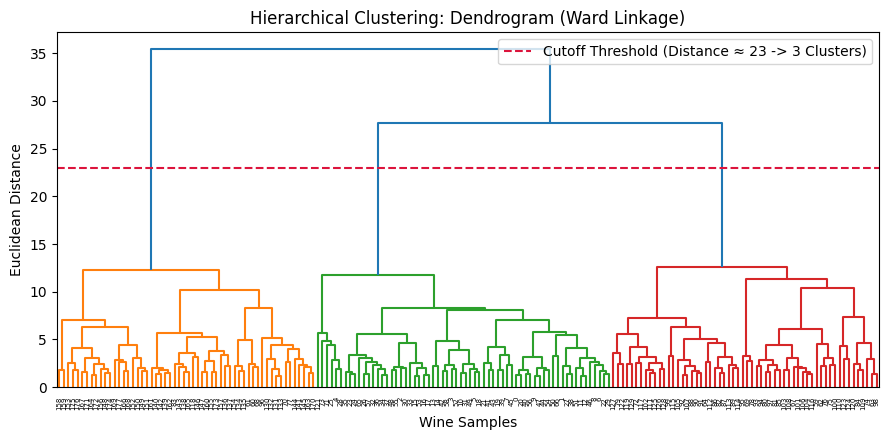

In [12]:
# Compute Silhouette scores for k = 2 to 10
silhouette_agg = {}
for k in range(2, 11):
    agg = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = agg.fit_predict(X_scaled)
    silhouette_agg[k] = silhouette_score(X_scaled, labels)

for k, s in silhouette_agg.items():
    print(f"k = {k:2d} | Agglomerative Silhouette = {s:.4f}")

# Plot Dendrogram
plt.figure(figsize=(9, 4.5))
linkage_matrix = sch.linkage(X_scaled, method='ward')
dendrogram = sch.dendrogram(linkage_matrix)
plt.axhline(y=23, color='crimson', linestyle='--', label='Cutoff Threshold (Distance ≈ 23 -> 3 Clusters)')
plt.title('Hierarchical Clustering: Dendrogram (Ward Linkage)')
plt.xlabel('Wine Samples')
plt.ylabel('Euclidean Distance')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
agg_model = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)
df['Cluster_Agglomerative'] = agg_labels

print("Optimum Clusters: 3")
print(f"Silhouette Score: {silhouette_score(X_scaled, agg_labels):.4f}")
print("Cluster distribution:\n", df['Cluster_Agglomerative'].value_counts())

Optimum Clusters: 3
Silhouette Score: 0.2774
Cluster distribution:
 Cluster_Agglomerative
2    64
0    58
1    56
Name: count, dtype: int64


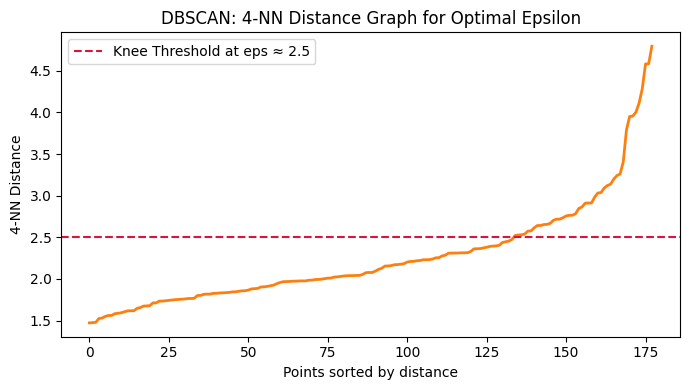

In [14]:
# 4-NN distance graph
k_nn = 4
neighbors = NearestNeighbors(n_neighbors=k_nn)
neighbors_fit = neighbors.fit(X_scaled)
distances, _ = neighbors_fit.kneighbors(X_scaled)

sorted_distances = np.sort(distances[:, k_nn - 1], axis=0)

plt.figure(figsize=(7, 4))
plt.plot(sorted_distances, color='#ff7f0e', linewidth=2)
plt.axhline(y=2.5, color='crimson', linestyle='--', label='Knee Threshold at eps ≈ 2.5')
plt.title('DBSCAN: 4-NN Distance Graph for Optimal Epsilon')
plt.xlabel('Points sorted by distance')
plt.ylabel('4-NN Distance')
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
dbscan_model = DBSCAN(eps=2.5, min_samples=4)
dbscan_labels = dbscan_model.fit_predict(X_scaled)
df['Cluster_DBSCAN'] = dbscan_labels

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_db = list(dbscan_labels).count(-1)

print(f"Optimal Parameters: eps = 2.5, min_samples = 4")
print(f"Clusters Formed: {n_clusters_db}")
print(f"Noise/Outlier Points Flagged: {n_noise_db} ({n_noise_db/len(df)*100:.2f}%)")
print(f"Silhouette Score: {silhouette_score(X_scaled, dbscan_labels):.4f}")
print("Cluster distribution:\n", df['Cluster_DBSCAN'].value_counts())

Optimal Parameters: eps = 2.5, min_samples = 4
Clusters Formed: 1
Noise/Outlier Points Flagged: 23 (12.92%)
Silhouette Score: 0.1352
Cluster distribution:
 Cluster_DBSCAN
 0    155
-1     23
Name: count, dtype: int64


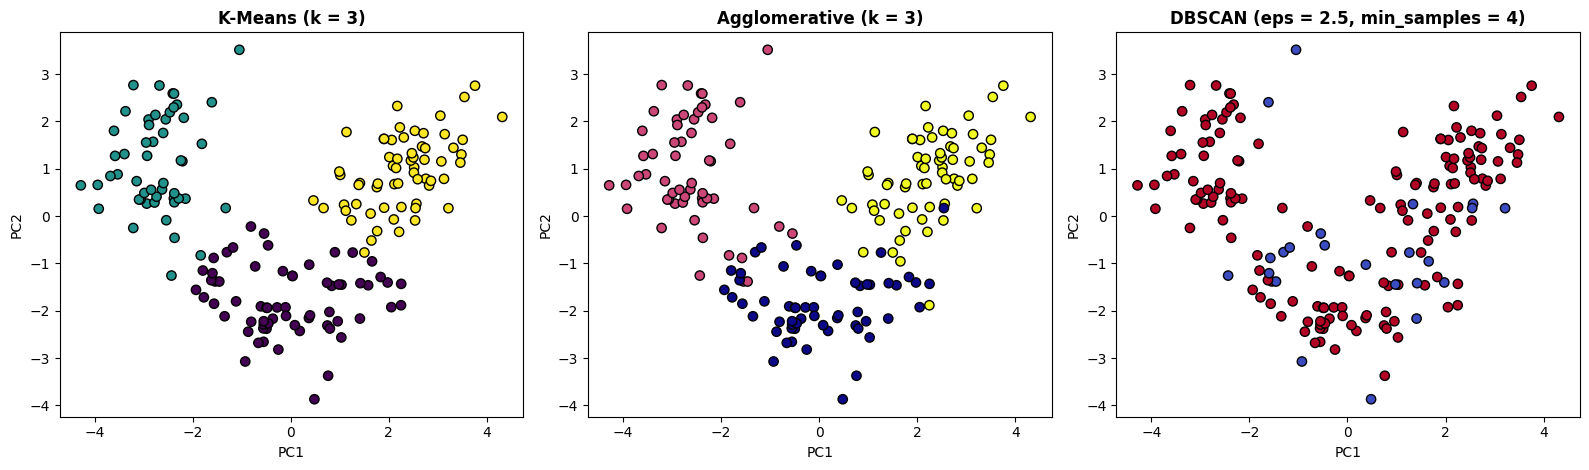

In [16]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# K-Means PCA
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=45, edgecolors='k')
axes[0].set_title('K-Means (k = 3)', fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# Agglomerative PCA
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='plasma', s=45, edgecolors='k')
axes[1].set_title('Agglomerative (k = 3)', fontweight='bold')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

# DBSCAN PCA
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='coolwarm', s=45, edgecolors='k')
axes[2].set_title('DBSCAN (eps = 2.5, min_samples = 4)', fontweight='bold')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')

plt.tight_layout()
plt.show()